In [1]:
# Cell 1: Import Required Libraries for Kaggle Environment
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import tensorflow.keras.backend as K
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, classification_report

print(f"TensorFlow Version: {tf.__version__}")

2026-06-07 10:30:39.864181: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780828240.076010      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780828240.137041      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780828240.635522      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780828240.635567      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780828240.635570      58 computation_placer.cc:177] computation placer alr

TensorFlow Version: 2.19.0


In [3]:
# Cell 2: Load Data using tf.data Pipeline directly from Kaggle Input
IMG_SIZE = 128  #  (128x128)
BATCH_SIZE = 32

# Directory paths 
TRAIN_IMG_DIR = '/kaggle/input/datasets/leoscode/wound-segmentation-images/data_wound_seg/train_images'
TRAIN_MASK_DIR = '/kaggle/input/datasets/leoscode/wound-segmentation-images/data_wound_seg/train_masks'

TEST_IMG_DIR = '/kaggle/input/datasets/leoscode/wound-segmentation-images/data_wound_seg/test_images'
TEST_MASK_DIR = '/kaggle/input/datasets/leoscode/wound-segmentation-images/data_wound_seg/test_masks'

# Verify if paths exist
if not os.path.exists(TRAIN_IMG_DIR) or not os.path.exists(TRAIN_MASK_DIR):
    print("ERROR: Directories not found. Please check paths.")
else:
    # Read and sort file names
    train_image_files = sorted([os.path.join(TRAIN_IMG_DIR, f) for f in os.listdir(TRAIN_IMG_DIR) if f.endswith(('.png', '.jpg', '.jpeg'))])
    train_mask_files = sorted([os.path.join(TRAIN_MASK_DIR, f) for f in os.listdir(TRAIN_MASK_DIR) if f.endswith(('.png', '.jpg', '.jpeg'))])
    
    test_image_files = sorted([os.path.join(TEST_IMG_DIR, f) for f in os.listdir(TEST_IMG_DIR) if f.endswith(('.png', '.jpg', '.jpeg'))])
    test_mask_files = sorted([os.path.join(TEST_MASK_DIR, f) for f in os.listdir(TEST_MASK_DIR) if f.endswith(('.png', '.jpg', '.jpeg'))])

    print(f"Training Data: {len(train_image_files)} Images | {len(train_mask_files)} Masks")
    print(f"Testing Data: {len(test_image_files)} Images | {len(test_mask_files)} Masks")

def process_path(img_path, mask_path):
    # Process Image 
    img = tf.io.read_file(img_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    img = img / 255.0

    # Process Mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_image(mask, channels=1, expand_animations=False)
    mask = tf.image.resize(mask, [IMG_SIZE, IMG_SIZE], method='nearest')
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    mask = tf.cast(mask > 127, tf.float32)
    
    return img, mask

def create_dataset(image_paths, mask_paths):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    dataset = dataset.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

# Create fast tf.data pipelines
if 'train_image_files' in locals():
    train_dataset = create_dataset(train_image_files, train_mask_files)
    test_dataset = create_dataset(test_image_files, test_mask_files)
    print("Fast tf.data pipelines created successfully!")

Training Data: 2208 Images | 2208 Masks
Testing Data: 552 Images | 552 Masks


I0000 00:00:1780828452.055070      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1780828452.061344      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Fast tf.data pipelines created successfully!


In [4]:
# Cell 3: Custom Loss Functions for Imbalanced Segmentation
def tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, smooth=1e-6):
    y_true_f = K.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = K.flatten(y_pred)
    true_pos = K.sum(y_true_f * y_pred_f)
    false_neg = K.sum(y_true_f * (1 - y_pred_f))
    false_pos = K.sum((1 - y_true_f) * y_pred_f)
    return 1 - ((true_pos + smooth) / (true_pos + alpha * false_neg + beta * false_pos + smooth))

def hybrid_loss(y_true, y_pred):
    t_loss = tversky_loss(y_true, y_pred)
    bce_loss = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return (0.75 * t_loss) + (0.25 * bce_loss)

In [5]:
# Cell 4: Lightweight U-Net Model Definition 
def conv_block(input_tensor, num_filters):
    x = layers.Conv2D(num_filters, (3, 3), padding='same')(input_tensor)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(num_filters, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x

def build_unet(input_shape=(128, 128, 3)):
    inputs = layers.Input(input_shape)
    
    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)
    
    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)
    
    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D((2, 2))(c3)
    
    # Bottleneck (256 filters)
    c4 = conv_block(p3, 256)
    c4 = layers.Dropout(0.3)(c4)
    
    # Decoder
    u5 = layers.UpSampling2D((2, 2))(c4)
    u5 = layers.Concatenate()([u5, c3])
    c5 = conv_block(u5, 128)
    
    u6 = layers.UpSampling2D((2, 2))(c5)
    u6 = layers.Concatenate()([u6, c2])
    c6 = conv_block(u6, 64)
    
    u7 = layers.UpSampling2D((2, 2))(c6)
    u7 = layers.Concatenate()([u7, c1])
    c7 = conv_block(u7, 32)
    
    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid')(c7)
    return models.Model(inputs=[inputs], outputs=[outputs])

unet_model = build_unet()
unet_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss=hybrid_loss)
unet_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_4[0][0]  

 Total params: 1,952,513 (7.45 MB)

 Trainable params: 1,949,697 (7.44 MB)

 Non-trainable params: 2,816 (11.00 KB)

In [6]:
# Cell 5: Train and Save the Model 
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

MODEL_SAVE_PATH = '/kaggle/working/best_unet_model.h5'

callbacks = [
    ModelCheckpoint(MODEL_SAVE_PATH, verbose=1, save_best_only=True, monitor='val_loss', mode='min'),
    EarlyStopping(patience=10, restore_best_weights=True, monitor='val_loss', mode='min'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
]

print("Starting Training Process...")
history = unet_model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=50,
    callbacks=callbacks
)

print(f"\nTraining Complete! Model saved successfully at: {MODEL_SAVE_PATH}")

Starting Training Process...
Epoch 1/50


I0000 00:00:1780828520.024142     154 service.cc:152] XLA service 0x7dc200011c50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1780828520.024179     154 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1780828520.024184     154 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1780828521.821529     154 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-07 10:35:27.794612: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-07 10:35:28.093143: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-07 10:35:29.762304: E external/local_xl

 1/69 ━━━━━━━━━━━━━━━━━━━━ 35:35 31s/step - loss: 0.9117

I0000 00:00:1780828542.716274     154 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - loss: 0.7980
Epoch 1: val_loss improved from None to 0.84237, saving model to /kaggle/working/best_unet_model.h5



Epoch 1: finished saving model to /kaggle/working/best_unet_model.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 51s 284ms/step - loss: 0.7202 - val_loss: 0.8424 - learning_rate: 1.0000e-04
Epoch 2/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - loss: 0.7096
Epoch 2: val_loss improved from 0.84237 to 0.79987, saving model to /kaggle/working/best_unet_model.h5


... (25 outputs left out)


Epoch 42: finished saving model to /kaggle/working/best_unet_model.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 174ms/step - loss: 0.0870 - val_loss: 0.2026 - learning_rate: 1.0000e-04
Epoch 43/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.1053
Epoch 43: val_loss did not improve from 0.20256
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 165ms/step - loss: 0.0856 - val_loss: 0.2082 - learning_rate: 1.0000e-04
Epoch 44/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.0993
Epoch 44: val_loss did not improve from 0.20256
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 166ms/step - loss: 0.0806 - val_loss: 0.2080 - learning_rate: 1.0000e-04
Epoch 45/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.0954
Epoch 45: val_loss did not improve from 0.20256
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 166ms/step - loss: 0.0768 - val_loss: 0.2080 - learning_rate: 1.0000e-04
Epoch 46/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.0920
Epoch 46: val_loss did not improve from 0.20256
69/69 ━━━━━━━━━━━━━━━━━━━━ 11s 165ms/step - loss:


Epoch 48: finished saving model to /kaggle/working/best_unet_model.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 169ms/step - loss: 0.0734 - val_loss: 0.1980 - learning_rate: 5.0000e-05
Epoch 49/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.0919
Epoch 49: val_loss improved from 0.19796 to 0.19436, saving model to /kaggle/working/best_unet_model.h5



Epoch 49: finished saving model to /kaggle/working/best_unet_model.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 169ms/step - loss: 0.0724 - val_loss: 0.1944 - learning_rate: 5.0000e-05
Epoch 50/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.0887
Epoch 50: val_loss improved from 0.19436 to 0.19363, saving model to /kaggle/working/best_unet_model.h5



Epoch 50: finished saving model to /kaggle/working/best_unet_model.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 169ms/step - loss: 0.0704 - val_loss: 0.1936 - learning_rate: 5.0000e-05

Training Complete! Model saved successfully at: /kaggle/working/best_unet_model.h5


Generating predictions for the test dataset...

--- PIXEL-WISE CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

  Background       1.00      1.00      1.00   8922583
  Wound Area       0.71      0.82      0.76    121385

    accuracy                           0.99   9043968
   macro avg       0.86      0.91      0.88   9043968
weighted avg       0.99      0.99      0.99   9043968



<Figure size 600x600 with 0 Axes>

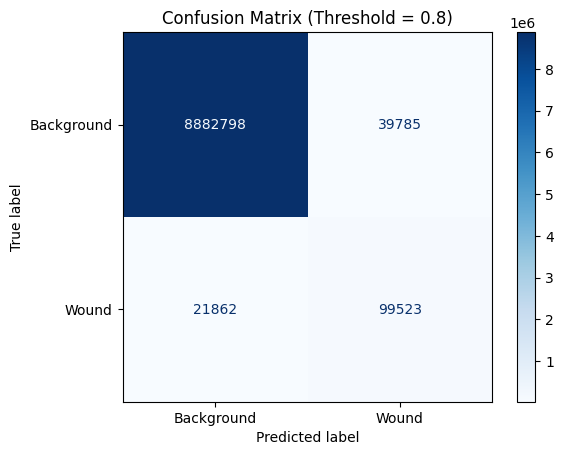

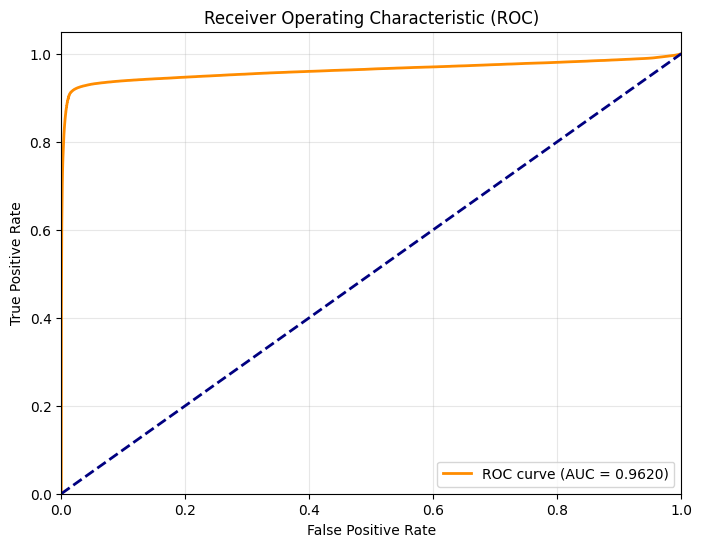

In [7]:
# Cell 6: Extract Predictions and Evaluate using Scikit-Learn
print("Generating predictions for the test dataset...")
THRESHOLD = 0.80  

y_true_list = []
y_pred_list = []

for images, masks in test_dataset:
    preds = unet_model.predict(images, verbose=0)
    y_true_list.append(masks.numpy())
    y_pred_list.append(preds)

y_test_flat = np.concatenate(y_true_list).flatten()
y_pred_flat = np.concatenate(y_pred_list).flatten()
y_pred_bin_flat = (y_pred_flat > THRESHOLD).astype(np.float32)

print("\n--- PIXEL-WISE CLASSIFICATION REPORT ---")
print(classification_report(y_test_flat, y_pred_bin_flat, target_names=['Background', 'Wound Area']))

cm = confusion_matrix(y_test_flat, y_pred_bin_flat)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Background', 'Wound'])
plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title(f'Confusion Matrix (Threshold = {THRESHOLD})')
plt.show()

fpr, tpr, _ = roc_curve(y_test_flat, y_pred_flat)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


Generating visual sample predictions...


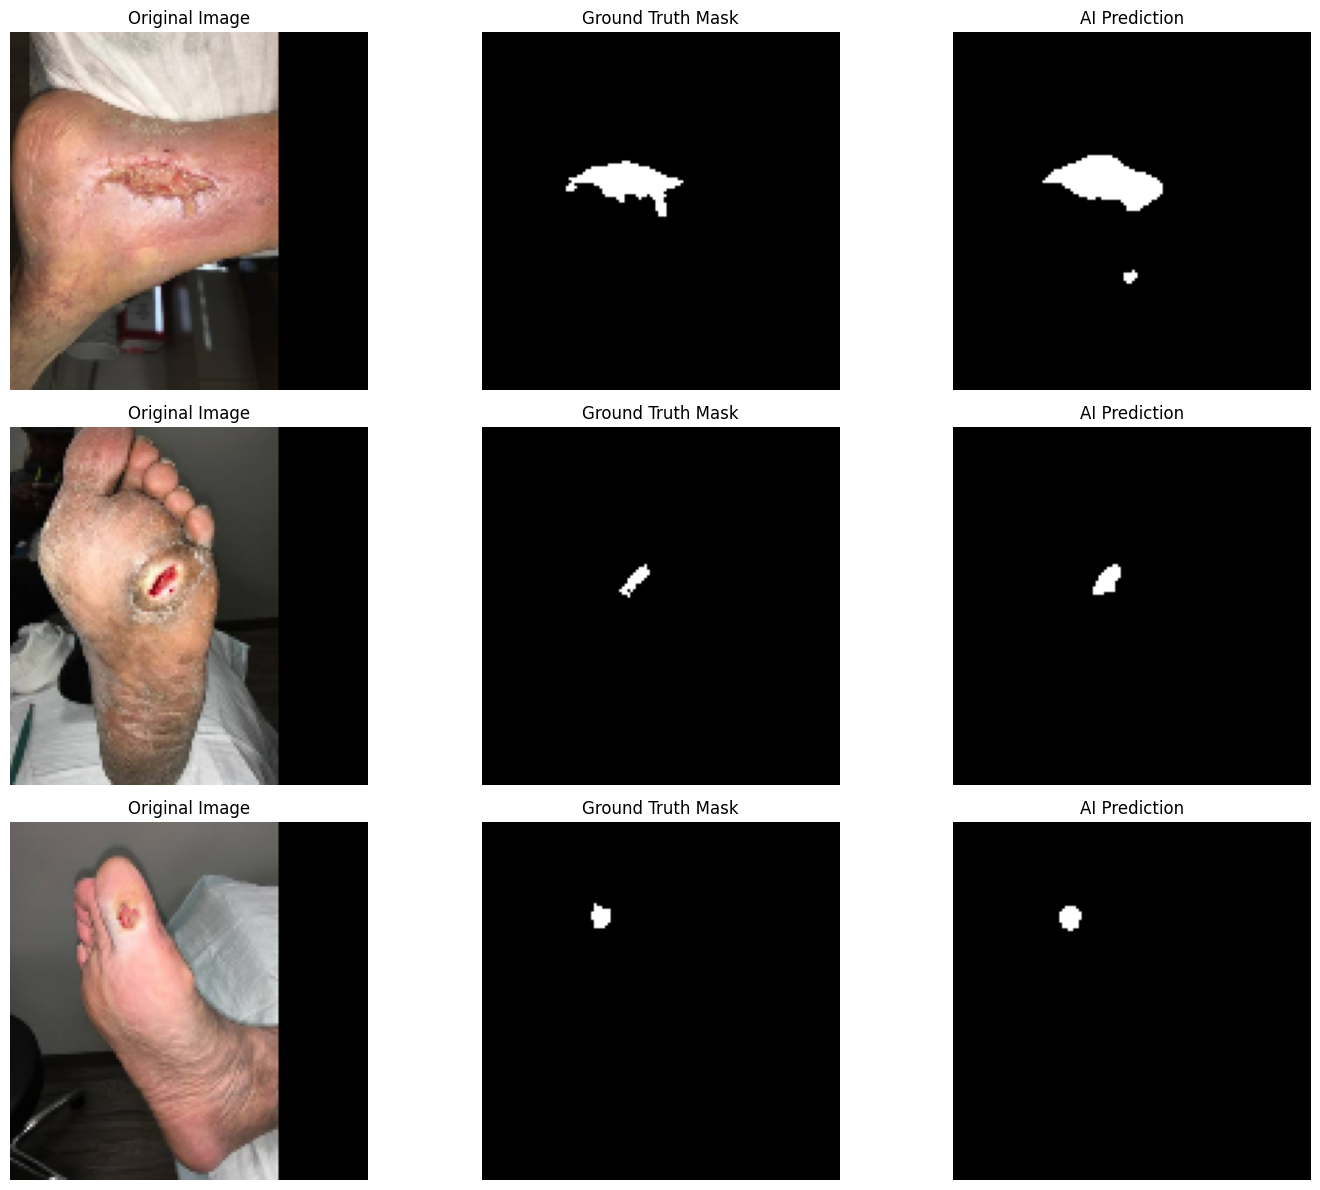

In [12]:
# Cell 7: Visual Evaluation of the Model
import random

def plot_predictions(dataset, model, num_samples=3):
    plt.figure(figsize=(15, 4 * num_samples))
    
    for images, masks in dataset.take(1):
        batch_size = images.shape[0]
        
        for i in range(num_samples):
            idx = random.randint(0, batch_size - 1)
            test_img = images[idx].numpy()
            actual_mask = masks[idx].numpy()
            
            pred_mask = model.predict(np.expand_dims(test_img, axis=0), verbose=0)[0]
            pred_mask_binary = (pred_mask > 0.80).astype(np.float32) 
            
            plt.subplot(num_samples, 3, i*3 + 1)
            plt.imshow(test_img)
            plt.title("Original Image")
            plt.axis('off')
            
            plt.subplot(num_samples, 3, i*3 + 2)
            plt.imshow(actual_mask.squeeze(), cmap='gray')
            plt.title("Ground Truth Mask")
            plt.axis('off')
            
            plt.subplot(num_samples, 3, i*3 + 3)
            plt.imshow(pred_mask_binary.squeeze(), cmap='gray')
            plt.title("AI Prediction")
            plt.axis('off')
            
    plt.tight_layout()
    plt.show()

print("\nGenerating visual sample predictions...")
plot_predictions(test_dataset, unet_model)